# Notebook 1: Raw Data Inspection and Cleaning Pipeline (House 1)

## Objective
This notebook fulfills **Section 1** of the Flock Energy take-home assignment. It implements a manageable, reproducible data-handling pipeline for the raw REFIT Electrical Load Measurements dataset, specifically focusing on **House 1**[cite: 1].

## Workflow & Key Steps
1. **Drive & Dataset Initialization:** Mounts Google Drive and extracts the raw `.7z` dataset archive[cite: 1].
2. **Timestamp Inspection & Deduplication:** Parses timestamps, verifies chronological ordering, and removes duplicate entries using a strict "keep-first" rule[cite: 1].
3. **Outlier Correction:** Identifies and neutralizes physically impossible or extreme values (such as negative power readings caused by sensor anomalies)[cite: 1].
4. **Resampling:** Aggregates irregular raw readings (sampled every 6–8 seconds) down to a consistent **1-minute resolution** using mean aggregation[cite: 1].
5. **Gap Filling & Outage Flagging:** Applies linear interpolation for short missing gaps ($\le$ 15 minutes) while systematically flagging prolonged outages rather than blindly filling them without justification[cite: 1].
6. **Visualization:** Plots 24-hour traces of whole-home aggregate power and select appliance channels both **before and after cleaning** to validate the pipeline[cite: 1].

**Install Dependencies & Mount Google Drive**

In [7]:
# Install required library for handling .7z archives
!pip install -q py7zr

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Extract Raw Dataset from Google Drive**

In [6]:
import os
import py7zr

RAW_ARCHIVE = "/content/drive/MyDrive/Flock Energy - Take Home Assignment /REFIT_RAW_081116.7z"
RAW_DIR = "/content/data/raw"
os.makedirs(RAW_DIR, exist_ok=True)

if not os.path.exists(os.path.join(RAW_DIR, "House1.csv")):
    print("Extracting Raw Dataset from Google Drive...")
    with py7zr.SevenZipFile(RAW_ARCHIVE, mode='r') as z:
        z.extractall(RAW_DIR)
print("Raw Dataset Extracted and Ready.")

Extracting Raw Dataset from Google Drive...
Raw Dataset Extracted and Ready.


**Load Raw House 1 Data & Inspect Timestamps**

In [8]:
import glob
import pandas as pd

# Locate House 1 raw file
raw_files = glob.glob(f"{RAW_DIR}/**/*.csv", recursive=True)
house1_path = [f for f in raw_files if "House1" in f or "House 1" in f][0]

print(f"Loading House 1 from: {house1_path}")
df_raw = pd.read_csv(house1_path)

# Parse timestamp column and set as index
time_col = [c for c in df_raw.columns if "time" in c.lower() or "date" in c.lower()][0]
df_raw[time_col] = pd.to_datetime(df_raw[time_col])
df_raw = df_raw.sort_values(by=time_col).set_index(time_col)

print(f"Raw House 1 Data Shape: {df_raw.shape}")
print("Columns found:", df_raw.columns.tolist())
display(df_raw.head())

Loading House 1 from: /content/data/raw/RAW_House12_Part1.csv
Raw House 1 Data Shape: (2865207, 11)
Columns found: ['Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9']


,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
Time,,,,,,,,,,,
2014-03-07 10:52:15,1394189535,138,0,5,1,0,0,0,0.0,0.0,0.0
2014-03-07 10:52:25,1394189544,137,0,5,1,0,0,0,NaN,NaN,NaN
2014-03-07 10:52:35,1394189555,139,0,5,1,0,0,0,NaN,NaN,NaN
2014-03-07 10:52:45,1394189564,138,0,5,1,0,0,0,NaN,NaN,NaN
2014-03-07 10:52:56,1394189575,138,0,4,1,0,0,0,NaN,NaN,NaN


**Data Cleaning Pipeline: Duplicates, Outliers, Resampling, Gaps**

In [9]:
import numpy as np

# 1. Check and remove duplicate timestamps
initial_len = len(df_raw)
duplicates = df_raw.index.duplicated().sum()
df_raw = df_raw[~df_raw.index.duplicated(keep='first')]
print(f"Removed {duplicates} duplicate timestamps out of {initial_len} total rows.")

# 2. Handle impossible/extreme negative values by setting them to 0
num_cols = df_raw.select_dtypes(include=[np.number]).columns
negative_counts = (df_raw[num_cols] < 0).sum().sum()
print(f"Total negative/extreme power instances corrected: {negative_counts}")
df_raw[num_cols] = df_raw[num_cols].apply(lambda x: np.where(x < 0, 0, x))

# 3. Resample to 1-minute intervals (mean aggregation)
df_1min = df_raw.resample('1min').mean()

# 4. Handle short gaps (linear interpolation up to 15 mins) and flag longer outages
df_cleaned = df_1min.interpolate(method='time', limit=15)
df_cleaned['long_outage_flag'] = df_raw[num_cols].isnull().resample('1min').mean().any(axis=1)

print(f"Final Resampled & Cleaned Dataset Shape: {df_cleaned.shape}")

Removed 76128 duplicate timestamps out of 2865207 total rows.
Total negative/extreme power instances corrected: 0
Final Resampled & Cleaned Dataset Shape: (298748, 12)


**Visualization: Before vs. After Cleaning**

Plotting for window: slice('2014-03-07 00:00:00', '2014-03-07 23:59:00', None)


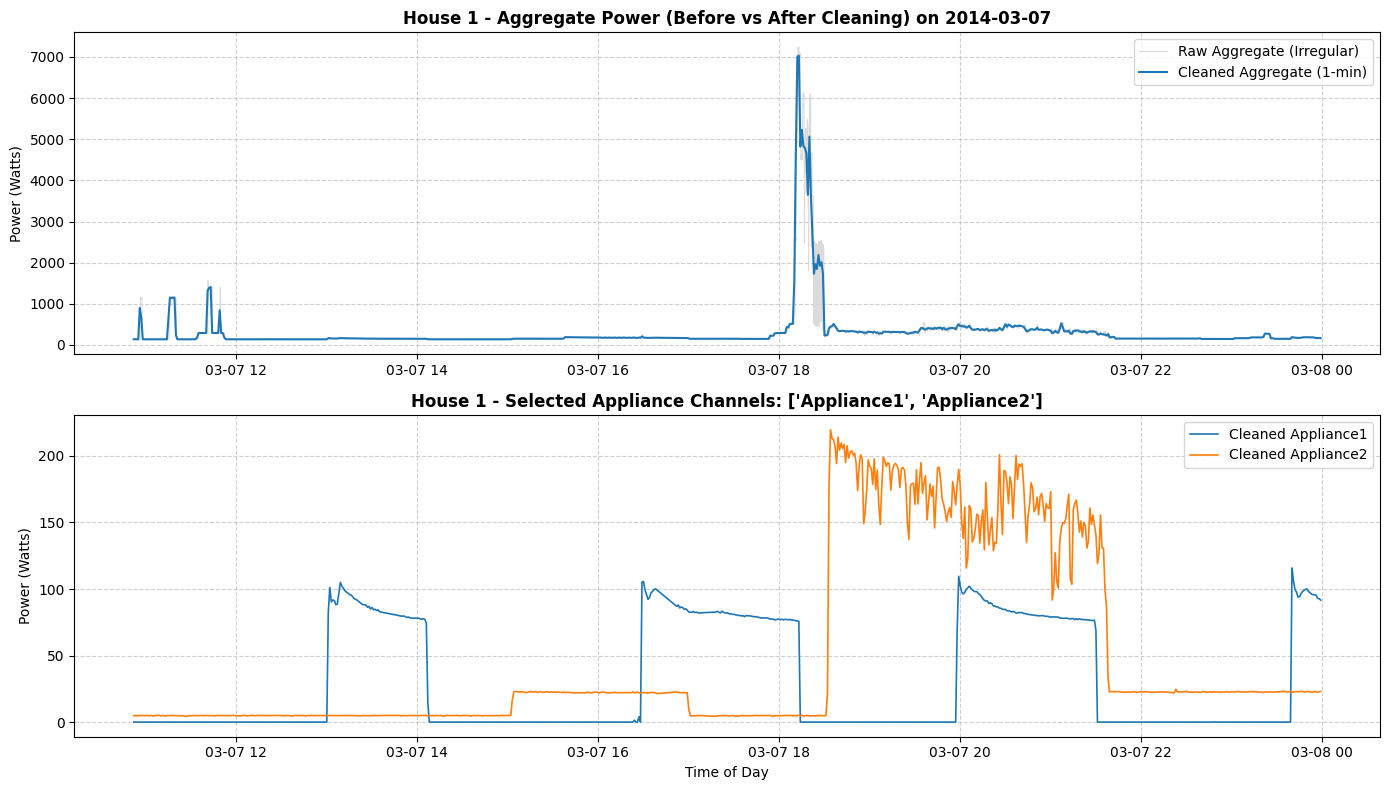

In [11]:
import matplotlib.pyplot as plt

# 1. Automatically find a busy day where aggregate power is greater than 0
active_days = df_cleaned[df_cleaned['Aggregate'] > 50].index.date
if len(active_days) > 0:
    target_date = active_days[10]  # Pick an active day
    sample_window = slice(str(target_date) + " 00:00:00", str(target_date) + " 23:59:00")
else:
    sample_window = slice("2014-03-07 00:00:00", "2014-03-07 23:59:00")

print(f"Plotting for window: {sample_window}")

# 2. Select two appliance columns for comparison
appliance_cols = [c for c in df_raw.columns if c not in ['Unix', 'Aggregate', 'Mains', 'long_outage_flag']][:2]

# 3. Create high-resolution plots
plt.figure(figsize=(14, 8), dpi=100)

# Subplot 1: Aggregate Power Before & After
plt.subplot(2, 1, 1)
plt.plot(df_raw.loc[sample_window].index, df_raw.loc[sample_window, 'Aggregate'], label='Raw Aggregate (Irregular)', color='lightgray', alpha=0.8, linewidth=0.8)
plt.plot(df_cleaned.loc[sample_window].index, df_cleaned.loc[sample_window, 'Aggregate'], label='Cleaned Aggregate (1-min)', color='#1f77b4', linewidth=1.5)
plt.title(f'House 1 - Aggregate Power (Before vs After Cleaning) on {target_date if "target_date" in locals() else "Sample Day"}', fontsize=12, fontweight='bold')
plt.ylabel('Power (Watts)')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Appliance Channels
plt.subplot(2, 1, 2)
for app in appliance_cols:
    plt.plot(df_cleaned.loc[sample_window].index, df_cleaned.loc[sample_window, app], label=f'Cleaned {app}', linewidth=1.2)
plt.title(f'House 1 - Selected Appliance Channels: {appliance_cols}', fontsize=12, fontweight='bold')
plt.xlabel('Time of Day')
plt.ylabel('Power (Watts)')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()